# Exploring Human Rights Council resolutions

Policy Pulse currently covers the General Assembly (GA). This notebook is a first, broad look at
the **Human Rights Council (HRC)**: how it works, what data exists for it, what that data shows,
and which of the site's GA features could carry over.

**What this notebook covers**
1. What the Human Rights Council is, and how it differs from the GA and the Security Council.
2. How the Council takes decisions, and how its documents are numbered.
3. Where HRC data comes from, and what is and is not available.
4. Downloading every HRC resolution (2006 to today) and checking the data.
5. First comparisons with the GA: consensus versus voting, agenda items, how close votes are, topics.
6. Which website features would work for the HRC, and what would be needed for the rest.

**Requirements:** an internet connection the first time (the download takes about four minutes and
is then saved to `notebooks/teju/data/hrc_resolutions.csv`), and the local database snapshot
running for the GA comparisons in sections 6 to 9 (`uv run init-env`, see the README).

In [1]:
import re
import time
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from IPython.display import display

# Locate the repository whether Jupyter starts here or at the repository root.
repo_root = next(
    (path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").is_file()),
    None,
)
assert repo_root is not None, "Start Jupyter from inside the policy-pulse repository."
data_file = repo_root / "notebooks/teju/data/hrc_resolutions.csv"

# Chart colours: the HRC in blue, the GA as a muted reference line.
HRC_COLOUR, GA_COLOUR = "#2a78d6", "#8a8984"
INK, MUTED_INK, GRID, SURFACE = "#0b0b0b", "#52514e", "#e5e4e0", "#fcfcfb"


def style_axes(ax, title):
    '''Quiet axes and grid so the data carries the chart.'''
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.tick_params(colors=MUTED_INK, labelsize=9)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.set_facecolor(SURFACE)
    ax.figure.set_facecolor(SURFACE)

## 1. What the Human Rights Council is

The Human Rights Council is the UN's main intergovernmental body on human rights. It is based in
**Geneva** and was created by **General Assembly resolution 60/251 (15 March 2006)**. It replaced
the **Commission on Human Rights** (1946–2006), which had been widely criticised for being
politicised and for including states with poor human rights records. The Council held its first
session in June 2006, so all HRC data starts then.

The Council is a **subsidiary body of the General Assembly**, not of the Economic and Social
Council as the Commission was. This is why the UN catalogue files its documents under "General
Assembly".

### Membership

- **47 member states**, elected by the GA by **secret ballot**. A candidate needs an **absolute
  majority of all GA members** (97 votes), not just a majority of those voting.
- Members serve **three-year terms**, and about a third of the seats are elected each year. A
  member cannot be re-elected immediately after two consecutive terms.
- Seats are shared out by **regional group**:

| Regional group | Seats |
|---|---:|
| African States | 13 |
| Asia-Pacific States | 13 |
| Latin American and Caribbean States | 8 |
| Western European and Other States | 7 |
| Eastern European States | 6 |

- The GA can **suspend** a member that commits gross and systematic violations of human rights, by a
  two-thirds majority. This has happened twice: **Libya (2011)** and the **Russian Federation (2022)**.
- **Any UN member can take part as an observer.** Observers can speak and can sponsor draft
  resolutions, but **only the 47 members vote**.

### Sessions

- At least **three regular sessions a year**, totalling at least ten weeks, usually around
  February–April, June–July and September–October. Sessions are numbered consecutively
  (session 1 in 2006, session 60 in 2025).
- **Special sessions** can be called at any time at the request of **one third of the members
  (16)**, usually in response to a crisis.
- The Council also runs the **Universal Periodic Review (UPR)**, a peer review of every UN member's
  human rights record. UPR outcomes are adopted as decisions, not resolutions, so they are mostly
  outside this notebook.

### Compared with the bodies Policy Pulse already knows

| | General Assembly | Security Council | Human Rights Council |
|---|---|---|---|
| Members | all 193 UN members | 15: 5 permanent, 10 elected for 2 years | 47, elected for 3 years |
| Who sits there changes? | only when states join or leave the UN | the 10 elected seats each year | about 16 seats each year |
| Veto | no | yes, for the 5 permanent members | no |
| Decision rule | majority of members present and voting (two thirds for "important questions") | 9 votes and no permanent-member veto | majority of members present and voting |
| Binding? | no (except internal matters such as the budget) | can be, under Chapter VII | no |
| Typical outputs per year | about 300 resolutions | about 50 resolutions | about 90–110 resolutions |

The key difference for Policy Pulse is the **changing membership**. In the GA almost every country
votes on almost every resolution. In the HRC, any given country votes only in the years it holds a
seat, and the 47 members in 2010 are a different set from the 47 in 2024.

## 2. How the Council takes decisions

### From draft to resolution

1. A state or a group of states (the **main sponsors**, often called the "core group" or
   "penholders") tables a **draft resolution**, numbered like `A/HRC/55/L.25` ("L" for limited
   distribution). Other states, including observers, can join as **co-sponsors**.
2. The draft is negotiated in informal consultations during the session, and may be revised
   (`L.25/Rev.1`) or amended.
3. At the end of the session the Council takes action on each draft:
   - **Adopted without a vote** (by consensus) if no member objects. This is the usual outcome.
   - **Adopted by recorded vote** if any member requests one. Each of the 47 members votes
     **yes, no or abstain**, and the record of who voted how is written in the Council's report
     on that session.
4. A resolution needs a **simple majority of the members present and voting**. Abstentions do not
   count as "voting", so a text can pass with, for example, 20 yes, 12 no and 15 abstentions.

Votes can also be taken on **amendments** and on **procedural motions** (for example a motion
not to take action on a draft). These are not in the data used here, which records only the final
outcome of each adopted resolution.

### How documents are numbered

| Symbol | Meaning |
|---|---|
| `A/HRC/RES/55/23` | resolution 23 adopted at the 55th regular session |
| `A/HRC/RES/S-36/1` | resolution 1 adopted at the 36th special session |
| `A/HRC/DEC/55/115` | a decision (usually procedural or a UPR outcome) |
| `A/HRC/PRST/55/1` | a statement by the President of the Council |
| `A/HRC/55/L.25` | a draft resolution |
| `A/HRC/RES/18/R.1` | a confidential resolution adopted in a closed meeting under the complaint procedure |

`A/` at the start marks the document as belonging to the General Assembly family, which again
reflects that the HRC is a GA subsidiary body.

### The agenda

Since 2007, every regular session follows the same **ten-item agenda** (set by resolution 5/1, the
"institution-building package"). Every resolution is adopted under one item, which tells us a lot
about what kind of text it is.

| Item | Topic |
|---:|---|
| 1 | Organizational and procedural matters |
| 2 | Annual report of the High Commissioner for Human Rights and reports of the Office and the Secretary-General |
| 3 | Promotion and protection of all human rights, civil, political, economic, social and cultural rights, including the right to development |
| 4 | Human rights situations that require the Council's attention |
| 5 | Human rights bodies and mechanisms |
| 6 | Universal Periodic Review |
| 7 | Human rights situation in Palestine and other occupied Arab territories |
| 8 | Follow-up to and implementation of the Vienna Declaration and Programme of Action |
| 9 | Racism, racial discrimination, xenophobia and related forms of intolerance, follow-up to the Durban Declaration and Programme of Action |
| 10 | Technical assistance and capacity-building |

Two contrasts are worth remembering for later. **Item 4** is where the Council addresses specific
countries critically, while **item 10** deals with countries through cooperation and technical
support, usually with the country's consent. **Item 7** is the only item dedicated to a single
situation, which some states have long objected to.

## 3. Where HRC data comes from

**The project database contains only General Assembly data.** The database design already allows for
other bodies (its `source_dataset` column is described as `'GA' | 'SC' | 'HRC' | ...`), but HRC
data has not been added yet.

The UN Digital Library publishes ready-made **voting datasets** (one row per country per resolution)
for the **GA and the SC only**. For the HRC there is no such dataset.

What does exist is the UN library **catalogue**: a record for every HRC document, available through
the same `metadata.un.org` service that the team's ingestion prototype
(`notebooks/janic/ingestion_prototype.py`) uses. Catalogue records use the library standard
**MARC**, where each piece of information sits in a numbered field. The fields used here:

| MARC field | Contents | Example |
|---|---|---|
| 001 | catalogue record id | `1404134` |
| 191 | document symbol and session | `A/HRC/RES/55/23`, session `55` |
| 245 | title | *Situation of human rights in Ukraine stemming from the Russian aggression* |
| 992 | date of adoption | `2024-04-04` |
| 996 | how it was adopted | `Adopted 27-3-17, 55th meeting` (yes–no–abstain) |
| 991 | agenda item | item `4`, *Human rights situations that require the Council's attention* |
| 650 | subject terms from the UN thesaurus (several per record) | `HUMAN RIGHTS`, `UKRAINE`, `COMMISSIONS OF INQUIRY` |
| 993 | related documents, including the draft | `A/HRC/55/L.25` |

So for every resolution we know **what** it was about, **when** and **under which agenda item** it
was adopted, **whether it went to a vote**, and the **totals**. We do **not** know **how each
country voted**: that is written as text in the annex of each session report, not published as
data.

### 3a. Download functions

`parse_record` turns one catalogue record (in MARC XML) into one row. `download_hrc_resolutions`
asks the catalogue for every record that is (a) catalogued as a resolution, (b) from the Human
Rights Council and (c) has a symbol starting `A/HRC/RES`, 200 records at a time.

In [2]:
API = "https://metadata.un.org/editor/api/marc/bibs/records"
QUERY = '989:Resolutions AND 981:"Human Rights Council" AND 191:A/HRC/RES*'


def parse_record(record):
    '''One MARC XML record -> one dict with the fields described in section 3.'''
    fields = {}
    for field in record.findall("datafield"):
        subfields = {sf.get("code"): (sf.text or "").strip() for sf in field.findall("subfield")}
        fields.setdefault(field.get("tag"), []).append(subfields)

    def first(tag, code):
        return (fields.get(tag) or [{}])[0].get(code)

    return {
        "record_id": record.findtext("controlfield[@tag='001']"),
        "resolution": first("191", "a"),
        "session": first("191", "c"),
        "title": first("245", "a"),
        "date": first("992", "a") or first("269", "a"),
        "vote_note": first("996", "a"),
        "agenda_item": first("991", "b"),
        "agenda_title": first("991", "c"),
        "subjects": "|".join(f.get("a", "") for f in fields.get("650", [])),
        "draft": first("993", "a"),
    }


def fetch_records(query, start=1, limit=200):
    response = requests.get(
        API,
        params={"search": query, "format": "xml", "subtype": "all", "start": start,
                "limit": limit, "sort": "updated", "direction": "asc"},
        timeout=180,
    )
    response.raise_for_status()
    return ET.fromstring(response.content).findall("record")


def download_hrc_resolutions(page_size=200):
    rows, start = [], 1
    while True:
        batch = fetch_records(QUERY, start=start, limit=page_size)
        rows.extend(parse_record(record) for record in batch)
        print(f"  {len(rows):,} records so far")
        if len(batch) < page_size:
            return pd.DataFrame(rows)
        start += page_size
        time.sleep(0.5)  # be polite to the UN server

### 3b. One record, before any cleaning

The Ukraine resolution from the table above, straight from the catalogue. This is a live request,
so it needs an internet connection.

In [3]:
try:
    example = fetch_records('191:"A/HRC/RES/55/23"', limit=1)
    display(pd.Series(parse_record(example[0]), name="A/HRC/RES/55/23").to_frame())
except requests.RequestException as error:
    print("Could not reach the UN catalogue:", error)

,A/HRC/RES/55/23
record_id,1404134
resolution,A/HRC/RES/55/23
session,55
title,Situation of human rights in Ukraine stemming ...
date,2024-04-04
vote_note,"Adopted 27-3-17, 55th meeting"
agenda_item,4
agenda_title,Human rights situations that require the Counc...
subjects,HUMAN RIGHTS|AGGRESSION|UKRAINE|RUSSIAN FEDERA...
draft,A/HRC/55/L.25


## 4. Load every HRC resolution

The first run downloads everything and saves it to `notebooks/teju/data/hrc_resolutions.csv`. Later
runs read the saved file, which is instant. To refresh the data, delete the file and rerun this cell.

In [4]:
if data_file.exists():
    hrc_raw = pd.read_csv(data_file, dtype=str)
    print(f"Read {len(hrc_raw):,} records from {data_file.relative_to(repo_root)}")
else:
    print("Downloading from the UN catalogue (about four minutes)...")
    hrc_raw = download_hrc_resolutions()
    data_file.parent.mkdir(parents=True, exist_ok=True)
    hrc_raw.to_csv(data_file, index=False)
    print(f"Saved {len(hrc_raw):,} records to {data_file.relative_to(repo_root)}")

display(hrc_raw.head())

Read 1,848 records from notebooks/teju/data/hrc_resolutions.csv


,record_id,resolution,session,title,date,vote_note,agenda_item,agenda_title,subjects,draft
0,835600,A/HRC/RES/OM/1/2,1,Human rights situation in the Occupied Palesti...,2007-06-20,"Adopted without vote, organizational meeting",NaN,NaN,MILITARY ACTIVITY|ISRAEL|TERRITORIES OCCUPIED ...,A/HRC/5/L.5
1,835601,A/HRC/RES/OM/1/3,1,Follow-up to resolution 4/8 of 30 March 2007 a...,2007-06-20,"Adopted without vote, organizational meeting",NaN,NaN,HUMAN RIGHTS|DARFUR (SUDAN)|SUDAN|GROUPS OF EX...,A/HRC/5/L.6
2,835599,A/HRC/RES/OM/1/1,1,Report of the United Nations High Commissioner...,2007-06-20,"Adopted without vote, organizational meeting",NaN,NaN,POST-CONFLICT RECONSTRUCTION|HUMAN RIGHTS|LEBA...,A/HRC/5/L.4
3,906027,A/HRC/RES/12/2,12,"Cooperation with the United Nations, its repre...",2009-10-01,"Adopted without vote, 30th meeting",2,Annual report of the United Nations High Commi...,HUMAN RIGHTS VIOLATIONS|INTIMIDATION|REPRISALS...,A/HRC/12/L.8
4,906035,A/HRC/RES/12/1,12,Open-ended Intergovernmental Working Group on ...,2009-10-01,"Adopted without vote, 30th meeting",1,Organizational and procedural matters.,HUMAN RIGHTS|WORKING GROUPS|CONSULTATIONS|CONF...,A/HRC/12/L.28


## 5. Clean and check the data

### 5a. Turn the text fields into columns we can analyse

- The vote note `Adopted 27-3-17, 55th meeting` becomes `yes = 27`, `no = 3`, `abstain = 17`. A note
  with only two numbers (`Adopted 46-1`) means there were no abstentions.
- `voted` is `True` for a recorded vote and `False` for adoption without a vote.
- `special_session` marks `S-` resolutions, and `confidential` the closed-meeting `R.` resolutions.
- Two records are corrections (`Corr.1`) to resolutions already in the data, so they are dropped.

In [5]:
hrc = hrc_raw[~hrc_raw["resolution"].str.contains("Corr", na=False)].copy()

hrc["date"] = pd.to_datetime(hrc["date"])
hrc["year"] = hrc["date"].dt.year
hrc["agenda_item"] = pd.to_numeric(hrc["agenda_item"], errors="coerce").astype("Int64")
hrc["special_session"] = hrc["resolution"].str.contains("/S-")
hrc["confidential"] = hrc["resolution"].str.contains(r"/R\.")

counts = hrc["vote_note"].str.extract(r"Adopted (\d+)-(\d+)(?:-(\d+))?").astype(float)
hrc["yes"], hrc["no"], hrc["abstain"] = counts[0], counts[1], counts[2]
hrc.loc[hrc["yes"].notna() & hrc["abstain"].isna(), "abstain"] = 0
hrc["voted"] = hrc["vote_note"].notna() & ~hrc["vote_note"].str.contains("without", case=False, na=False)
hrc["subject_list"] = hrc["subjects"].fillna("").str.split("|")

print(f"{len(hrc):,} resolutions adopted between {hrc['date'].min():%d %B %Y} and {hrc['date'].max():%d %B %Y}")
display(hrc[["resolution", "date", "agenda_item", "vote_note", "voted", "yes", "no", "abstain"]].head())

1,846 resolutions adopted between 29 June 2006 and 07 October 2026


,resolution,date,agenda_item,vote_note,voted,yes,no,abstain
0,A/HRC/RES/OM/1/2,2007-06-20,<NA>,"Adopted without vote, organizational meeting",False,NaN,NaN,NaN
1,A/HRC/RES/OM/1/3,2007-06-20,<NA>,"Adopted without vote, organizational meeting",False,NaN,NaN,NaN
2,A/HRC/RES/OM/1/1,2007-06-20,<NA>,"Adopted without vote, organizational meeting",False,NaN,NaN,NaN
3,A/HRC/RES/12/2,2009-10-01,2,"Adopted without vote, 30th meeting",False,NaN,NaN,NaN
4,A/HRC/RES/12/1,2009-10-01,1,"Adopted without vote, 30th meeting",False,NaN,NaN,NaN


### 5b. Is anything missing?

If the download is complete, each session's resolutions should be numbered 1, 2, 3, … with no
gaps. We also check that no vote adds up to more than 47, the number of members.

In [6]:
numbered = hrc["resolution"].str.extract(r"^A/HRC/RES/(S-)?(\d+)/(\d+)$").dropna(subset=[1])
numbered = numbered.assign(special=numbered[0].notna(), session=numbered[1].astype(int), number=numbered[2].astype(int))
per_session = numbered.groupby(["special", "session"])["number"].agg(["count", "max"])
gaps = per_session[per_session["count"] != per_session["max"]]
print("Sessions with gaps in the numbering:", len(gaps))

special_present = set(numbered.loc[numbered["special"], "session"])
print("Special sessions with no resolution in the data:", sorted(set(range(1, max(special_present) + 1)) - special_present))

total_cast = hrc[["yes", "no", "abstain"]].sum(axis=1, min_count=1)
print("Votes adding up to more than 47:", int((total_cast > 47).sum()))
print("Members present and voting in recorded votes: median", int(total_cast.median()), "lowest", int(total_cast.min()))

print("\nMissing values per column:")
display(hrc[["vote_note", "agenda_item", "subjects"]].isna().sum().rename("missing").to_frame())
print("Resolutions without an agenda item, by session:")
display(hrc.loc[hrc["agenda_item"].isna(), "session"].value_counts().head(12).rename("resolutions").to_frame().T)

Sessions with gaps in the numbering: 0
Special sessions with no resolution in the data: [4, 13]
Votes adding up to more than 47: 0
Members present and voting in recorded votes: median 47 lowest 42

Missing values per column:


,missing
vote_note,1
agenda_item,221
subjects,0


Resolutions without an agenda item, by session:


session,6,7,10,9,8,11,4,1,2,3,5,19sp
resolutions,37,36,33,19,14,12,10,8,5,4,2,1


**What the checks show**

- **No gaps** in the numbering of any session, so the download appears complete.
- **Special sessions 4 and 13** have no resolution. Session S-4 (Darfur, 2006) adopted a decision
  instead (`A/HRC/DEC/S-4/101`); S-13 (Haiti, 2010) is not in the catalogue as a resolution, which
  is worth checking.
- **No vote exceeds 47**, and most recorded votes have all 47 members taking part.
- One resolution (`A/HRC/RES/6/16`) has no vote note, so we cannot tell how it was adopted.
- **Agenda items are missing for most of the first eleven sessions (2006–2009).** Part of this is
  real (the ten-item agenda only started in 2007), but the catalogue also left it blank for many
  later records from that period. Agenda results below therefore mainly describe 2009 onwards.
- The data contains **11 confidential resolutions** from the complaint procedure (2011–2014),
  all adopted without a vote in closed meetings.

## 6. Overview: how much does the Council adopt?

Resolutions per year, split into regular and special sessions. 2006 is a partial year (the Council
started in June), and the latest year includes everything adopted up to the download.

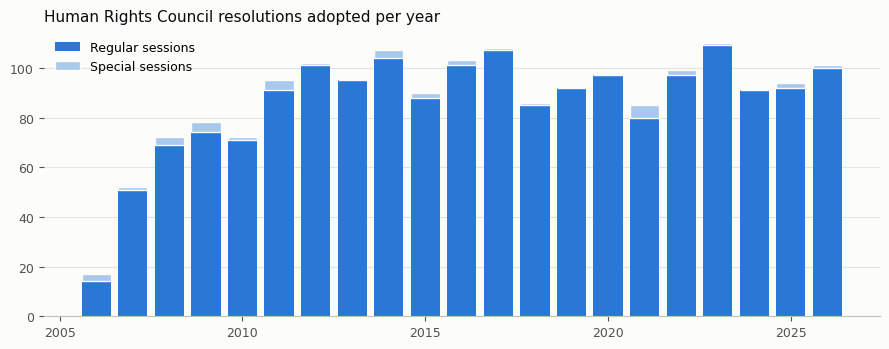

Average per full year (2007 onwards): 91
Special sessions held so far: 37 with resolutions


In [7]:
per_year = hrc.groupby(["year", "special_session"]).size().unstack(fill_value=0)
per_year.columns = ["regular sessions", "special sessions"]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(per_year.index, per_year["regular sessions"], color=HRC_COLOUR, width=0.8, label="Regular sessions")
ax.bar(per_year.index, per_year["special sessions"], bottom=per_year["regular sessions"],
       color="#a9c8ee", width=0.8, edgecolor=SURFACE, linewidth=1, label="Special sessions")
style_axes(ax, "Human Rights Council resolutions adopted per year")
ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()

print(f"Average per full year (2007 onwards): {per_year.loc[2007:hrc['year'].max() - 1].sum(axis=1).mean():.0f}")
print(f"Special sessions held so far: {numbered.loc[numbered['special'], 'session'].nunique()} with resolutions")

## 7. Consensus or vote, compared with the General Assembly

The share of resolutions adopted by **recorded vote** rather than without a vote is a simple
measure of how divided a body is. The GA side comes from the project database
(`resolution_outcomes.modality == "Vote, recorded"`), restricted to the same years.

In [8]:
from app.un_data_stream.data import db

db.load_env()
engine = db.create_engine()
with engine.connect() as conn:
    ga = pd.read_sql(
        '''SELECT undl_id, resolution, date, modality, total_yes, total_no, total_abstentions
           FROM resolution_outcomes WHERE date >= '2006-01-01' ''',
        conn, parse_dates=["date"],
    )
    ga_subjects = pd.read_sql(
        '''SELECT o.undl_id, o.modality, s.label_en AS subject
           FROM resolution_outcomes o
           JOIN resolution_subject rs USING (undl_id)
           JOIN subject s USING (subject_id)
           WHERE o.date >= '2006-01-01' ''',
        conn,
    )

ga["year"] = ga["date"].dt.year
ga["voted"] = ga["modality"].eq("Vote, recorded")
print(f"{len(ga):,} GA resolutions since 2006")

6,694 GA resolutions since 2006


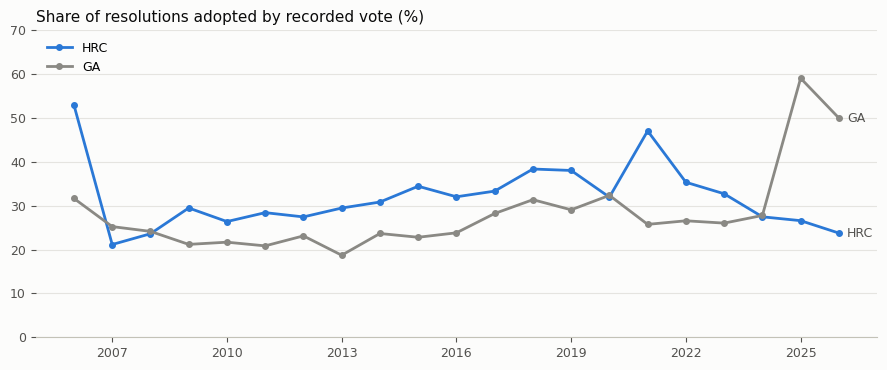

year,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
HRC,53,21,24,29,26,28,27,29,31,34,...,33,38,38,32,47,35,33,27,27,24
GA,32,25,24,21,22,21,23,19,24,23,...,28,31,29,32,26,27,26,28,59,50
HRC resolutions,17,52,72,78,72,95,102,95,107,90,...,108,86,92,97,85,99,110,91,94,101
GA resolutions,319,313,323,321,332,331,320,342,338,342,...,333,341,344,309,334,335,338,342,325,72


In [9]:
share_voted = pd.DataFrame({
    "HRC": hrc.groupby("year")["voted"].mean(),
    "GA": ga.groupby("year")["voted"].mean(),
    "HRC resolutions": hrc.groupby("year").size(),
    "GA resolutions": ga.groupby("year").size(),
})

fig, ax = plt.subplots(figsize=(9, 3.8))
for body, colour in [("HRC", HRC_COLOUR), ("GA", GA_COLOUR)]:
    ax.plot(share_voted.index, share_voted[body] * 100, color=colour, linewidth=2, marker="o", markersize=4, label=body)
    ax.annotate(body, (share_voted.index[-1], share_voted[body].iloc[-1] * 100), xytext=(6, 0),
                textcoords="offset points", color=MUTED_INK, fontsize=9, va="center")
style_axes(ax, "Share of resolutions adopted by recorded vote (%)")
ax.set_ylim(0, 70)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()

display((share_voted.assign(HRC=lambda d: (d["HRC"] * 100).round(), GA=lambda d: (d["GA"] * 100).round())
         .astype("Int64").T))

**Reading the chart**

- In almost every year from 2009 to 2023, the HRC went to a vote **more often than the GA**:
  typically about a third of its resolutions, against about a quarter in the GA.
- The HRC share **rose through the 2010s**, peaking in **2021 (47%)**, and has fallen since 2023.
- The GA jumps to about **59% in 2025**. That is a large break from two decades of stable values.
  One explanation to check is that some states began requesting recorded votes on texts that used
  to pass without one. It could also be partly a data effect: resolutions adopted without a vote may
  be catalogued later than recorded votes, which would also explain why 2026 looks high. **Check
  this before drawing conclusions.**
- 2006 has only 17 HRC resolutions, so its high value is not meaningful.

## 8. Agenda items: where does the Council divide?

The share of resolutions put to a vote under each agenda item, from 2009 onwards when agenda items
are recorded consistently.

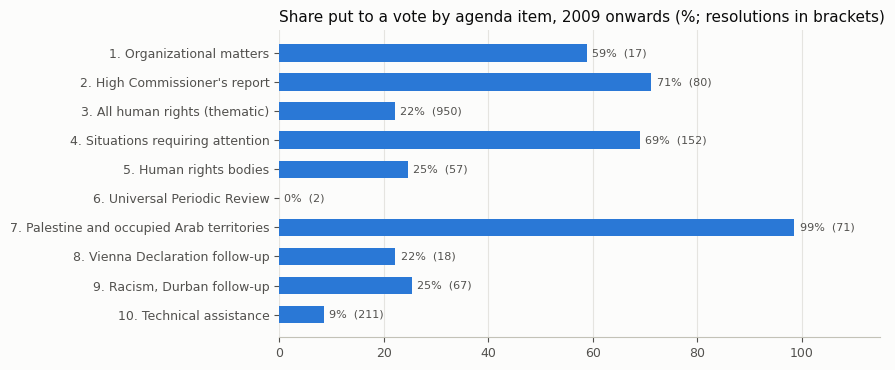

In [10]:
agenda_names = {
    1: "Organizational matters", 2: "High Commissioner's report", 3: "All human rights (thematic)",
    4: "Situations requiring attention", 5: "Human rights bodies", 6: "Universal Periodic Review",
    7: "Palestine and occupied Arab territories", 8: "Vienna Declaration follow-up",
    9: "Racism, Durban follow-up", 10: "Technical assistance",
}
by_item = (hrc[hrc["year"] >= 2009].dropna(subset=["agenda_item"])
           .groupby("agenda_item")
           .agg(resolutions=("voted", "size"), share_voted=("voted", "mean")))
by_item.insert(0, "item", by_item.index.map(agenda_names))

fig, ax = plt.subplots(figsize=(9, 3.8))
labels = [f"{i}. {agenda_names[i]}" for i in by_item.index]
ax.barh(labels, by_item["share_voted"] * 100, color=HRC_COLOUR, height=0.6)
for y, (share, n) in enumerate(zip(by_item["share_voted"], by_item["resolutions"])):
    ax.text(share * 100 + 1, y, f"{share:.0%}  ({n})", va="center", fontsize=8, color=MUTED_INK)
ax.invert_yaxis()
style_axes(ax, "Share put to a vote by agenda item, 2009 onwards (%; resolutions in brackets)")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_xlim(0, 115)
plt.tight_layout()
plt.show()

**Reading the chart**

- **Item 7 (Palestine) is almost always voted** (about 99%), and **item 4 (country situations)**
  about two times in three. These are the Council's most divisive items.
- **Item 10 (technical assistance) is rarely voted** (under 10%), even though it also deals with
  specific countries. Whether a country is addressed under item 4 or item 10 is itself a political
  choice, and it largely decides whether a text will pass by consensus.
- **Item 3 (thematic rights)** is by far the largest item, and about one in five of its
  resolutions is voted. That one in five is where questions like economic rights versus civil and
  political rights, or the effects of sanctions, divide the Council.
- **Item 2** is voted surprisingly often (about 70%). Several country-specific resolutions are
  adopted under this item, which is worth looking into.

## 9. How close are the votes?

For recorded votes only: the **share of yes votes among all votes cast** (yes, no and abstain). In
both bodies a resolution passes if yes is greater than no, so many resolutions pass with less than
half of the votes cast being yes.

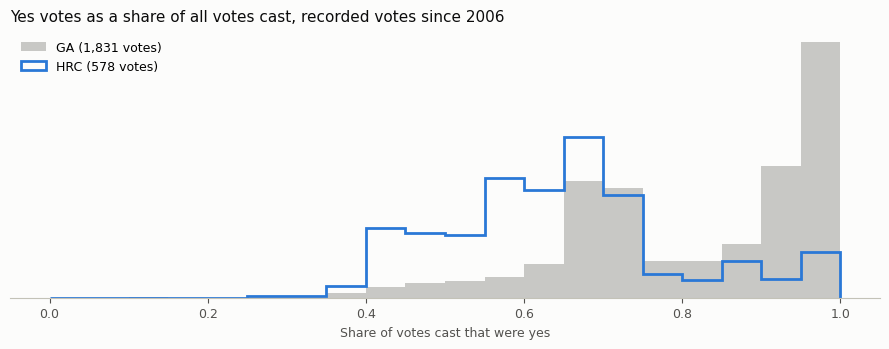

,HRC,GA
median share yes,64%,87%
median share abstaining,17%,5%
passed with less than half yes,18%,4%


In [11]:
hrc_votes = hrc[hrc["voted"] & hrc["yes"].notna()].copy()
hrc_votes["yes_share"] = hrc_votes["yes"] / hrc_votes[["yes", "no", "abstain"]].sum(axis=1)
hrc_votes["abstain_share"] = hrc_votes["abstain"] / hrc_votes[["yes", "no", "abstain"]].sum(axis=1)

ga_votes = ga[ga["voted"]].dropna(subset=["total_yes"]).copy()
ga_cast = ga_votes[["total_yes", "total_no", "total_abstentions"]].sum(axis=1)
ga_votes["yes_share"] = ga_votes["total_yes"] / ga_cast
ga_votes["abstain_share"] = ga_votes["total_abstentions"] / ga_cast

fig, ax = plt.subplots(figsize=(9, 3.6))
bins = [i / 20 for i in range(21)]
ax.hist(ga_votes["yes_share"], bins=bins, density=True, color=GA_COLOUR, alpha=0.45, label=f"GA ({len(ga_votes):,} votes)")
ax.hist(hrc_votes["yes_share"], bins=bins, density=True, histtype="step", linewidth=2, color=HRC_COLOUR,
        label=f"HRC ({len(hrc_votes):,} votes)")
style_axes(ax, "Yes votes as a share of all votes cast, recorded votes since 2006")
ax.set_xlabel("Share of votes cast that were yes", color=MUTED_INK, fontsize=9)
ax.set_yticks([])
ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "HRC": [hrc_votes["yes_share"].median(), hrc_votes["abstain_share"].median(), (hrc_votes["yes_share"] < 0.5).mean()],
    "GA": [ga_votes["yes_share"].median(), ga_votes["abstain_share"].median(), (ga_votes["yes_share"] < 0.5).mean()],
}, index=["median share yes", "median share abstaining", "passed with less than half yes"])
display(summary.map("{:.0%}".format))

**Reading the chart**

- **GA recorded votes are usually lopsided**: the typical one has 87% of votes cast as yes, and
  only 4% pass with less than half yes.
- **HRC votes are much closer.** The typical one has 64% yes and 17% abstentions (GA: 5%), and
  almost one in five HRC resolutions (18%) passes with less than half of the votes cast being yes.
- Part of this is arithmetic: in a 47-member body one regional group abstaining moves the share a
  lot. Part is political: the texts that go to a vote in Geneva are often the most contested ones,
  while many GA votes are on long-running resolutions with stable, predictable majorities.

## 10. Topics: what does the Council deal with?

Each HRC resolution has several subject terms from the **UN thesaurus**, the same vocabulary used in
the GA data. The most common ones:

In [12]:
hrc_subjects = hrc[["resolution", "voted", "subject_list"]].explode("subject_list").rename(columns={"subject_list": "subject"})
hrc_subjects = hrc_subjects[hrc_subjects["subject"] != ""]

print(f"{hrc_subjects['subject'].nunique():,} distinct subject terms; "
      f"{hrc_subjects.groupby('resolution').size().mean():.1f} per resolution on average")
display(hrc_subjects["subject"].value_counts().head(20).rename("resolutions").to_frame().T)

1,093 distinct subject terms; 8.8 per resolution on average


subject,HUMAN RIGHTS,HUMAN RIGHTS VIOLATIONS,SPECIAL RAPPORTEURS,TECHNICAL COOPERATION,REPORT PREPARATION,CONFERENCES,ANTI-DISCRIMINATION MEASURES,ACCOUNTABILITY,INTERNATIONAL OBLIGATIONS,INTERNATIONAL COOPERATION,EXPERTS,HUMANITARIAN ASSISTANCE,ADMINISTRATION OF JUSTICE,CRIME PREVENTION,INTERNAL SECURITY,CAPACITY BUILDING,HUMAN RIGHTS ADVANCEMENT,HUMAN RIGHTS IN ARMED CONFLICTS,WORKING GROUPS,TERRITORIES OCCUPIED BY ISRAEL
resolutions,1118,440,357,357,311,307,286,274,204,203,179,173,166,150,139,125,121,116,108,107


### Same topic, two arenas

For subjects that appear at least 15 times in **both** bodies since 2006: how often is each one put
to a vote?

**Note the difference in detail.** HRC records carry about nine subject terms each. GA records in the
project database carry about one, so the GA tags are broader. The comparison is a first indication,
not a like-for-like measure.

In [13]:
ga_subjects["voted"] = ga_subjects["modality"].eq("Vote, recorded")
print(f"GA: {ga_subjects.groupby('undl_id').size().mean():.1f} subject terms per resolution on average")

topic_comparison = (
    hrc_subjects.groupby("subject").agg(hrc_resolutions=("voted", "size"), hrc_share_voted=("voted", "mean"))
    .join(ga_subjects.groupby("subject").agg(ga_resolutions=("voted", "size"), ga_share_voted=("voted", "mean")), how="inner")
    .query("hrc_resolutions >= 15 and ga_resolutions >= 15")
)
topic_comparison["difference"] = topic_comparison["hrc_share_voted"] - topic_comparison["ga_share_voted"]
topic_comparison = topic_comparison.sort_values("difference")

shares = ["hrc_share_voted", "ga_share_voted", "difference"]
display(topic_comparison.style.format("{:.0%}", subset=shares).format("{:,.0f}", subset=["hrc_resolutions", "ga_resolutions"]))

GA: 1.2 subject terms per resolution on average


,hrc_resolutions,hrc_share_voted,ga_resolutions,ga_share_voted,difference
subject,,,,,
RACIAL DISCRIMINATION,81,37%,59,71%,-34%
HUMAN RIGHTS INSTITUTIONS,65,11%,21,43%,-32%
RIGHT TO FOOD,32,19%,20,45%,-26%
HUMAN RIGHTS ADVANCEMENT,121,18%,416,41%,-22%
RIGHT TO DEVELOPMENT,52,83%,20,100%,-17%
HUMAN RIGHTS,"1,118",33%,147,50%,-17%
PALESTINE QUESTION,28,89%,72,100%,-11%
SANCTIONS,21,90%,20,100%,-10%
POVERTY,26,0%,33,6%,-6%


**Reading the table** (sorted from "voted more in the GA" to "voted more in the HRC")

- **Divisive in both:** the occupied territories and the Palestine question, sanctions,
  mercenaries and the right to development are voted (almost) every time in both bodies. These
  follow long-standing North–South and Middle East divisions.
- **Voted much more often in Geneva:** external debt, international law, humanitarian assistance,
  terrorism, chemical weapons (the Syria resolutions) and self-determination.
- **Voted more often in New York:** racial discrimination, human rights institutions and the right
  to food.
- **Some differences are about tagging, not politics.** `PALESTINIANS` is voted 96% of the time in
  the HRC but 5% in the GA, almost certainly because the term is attached to different kinds of
  texts in the two datasets. Any topic that stands out needs a look at the actual resolutions.
- Topics on both lists are good candidates for a direct "same issue, two arenas" comparison: the
  same states negotiate them in Geneva and New York, often with similar texts.

## 11. Which website features would work for the HRC?

| Website feature | Works with the HRC data we have now? | What would be needed |
|---|---|---|
| Resolution list (browse, filter, search) | **Yes**: title, date, subjects, agenda item, outcome and totals | individual country votes for the per-country vote column |
| Word cloud of titles | **Yes** | nothing |
| General statistics (totals, years) | **Yes** | nothing |
| Consensus versus vote over time | **Yes** (section 7) | nothing; this would be a new feature for the GA too |
| Agenda item breakdown | **Yes** (section 8); this has no direct GA equivalent | nothing |
| Agreement map, agreement timeline, alignment by subject | **No** | how each country voted on each resolution |
| Multilateral scatter | **No** | country votes, and handling of members that only sit for some years |

**Methodological points for any HRC version of the agreement features**

- **Membership changes every year.** Two countries can only be compared in years when both held a
  seat, so many pairs will have very few comparable votes. The minimum-vote threshold used on the
  site (10 votes) would need to be revisited.
- **Who is on the Council is itself political.** A country's record in Geneva depends on whether it
  sought and won election, so an HRC agreement score describes the members, not all UN states.
- **The votes that happen are a selected set.** About two thirds of HRC resolutions pass without a
  vote, and the ones that are voted are disproportionately items 4 and 7. Agreement scores would
  describe the contested part of the agenda, which is also true in the GA, but more so here.

## 12. Next steps and open questions

**Getting country-level votes**
- The record of who voted how is in the annex of each session's report (`A/HRC/<session>/2`). It
  could be extracted from those documents, or an existing research dataset could be used, if one
  covers recent sessions. Both options need checking.
- A list of **members by year** is needed in any case (from the GA's election records or the
  Council's membership page), together with the two suspensions.

**Questions this first look raises**
- Why did the share of voted HRC resolutions rise in the 2010s and peak in 2021, and is the GA's
  jump in 2025 real or a cataloguing delay?
- **Item 4 versus item 10:** which countries are addressed under which item, and does it change over
  time (for example, moving from item 4 to item 10 as a situation improves, or the reverse)?
- **Special sessions:** what triggers them, and how often do they end in a vote?
- **Same issue, two arenas:** for topics on both agendas (section 10), do texts and majorities differ
  between Geneva and New York?

The cell below is free for further exploration.

In [14]:
# Scratch space.